# Suavizado de una serie temporal

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as stm

In [2]:
def parser(x):
	return  pd.to_datetime(x, format='%Y-%m-%dT%H:%M:%S')
df = pd.read_csv(
    "covid_navarra.csv",
    header=0,
    parse_dates=[1],
    index_col=1
)

df.head()

,_id,CasosConfirmadosVariacion24horas,AcumuladoCasosConfirmados,AcumuladoFallecimientos,FallecimientosVariacion24hs,NuevaHospitaliz,HospAcum,Nuevo UCI,UCI Acu,PruebasPCRTotales,PruebasPCRPositivas,PruebasPCR%Positivas,PruebasAntigenosTotales,PruebasAntigenosPositivas,PruebasAntigenos%Positivas
Fecha,,,,,,,,,,,,,,,
2020-06-30,1,5,5464,528,0,0,2047,0,137,966,8,"0,82999999999999996",120,12,10
2020-07-01,2,8,5472,528,0,0,2047,0,137,870,10,"1,1499999999999999",135,16,"11,85"
2020-07-02,3,3,5475,528,0,0,2047,0,137,804,6,"0,75",102,9,"8,8200000000000003"
2020-07-03,4,0,5475,528,0,1,2048,0,137,631,5,"0,79000000000000004",98,8,"8,1600000000000001"
2020-07-04,5,3,5478,528,0,1,2049,0,137,372,4,"1,0800000000000001",16,0,0


In [3]:
covid_cases= df["CasosConfirmadosVariacion24horas"]

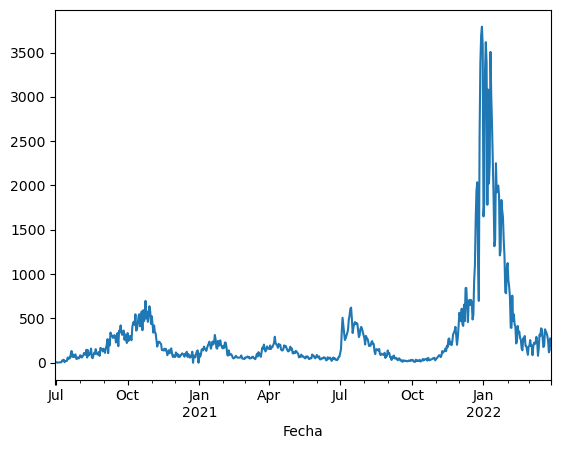

In [4]:
covid_cases.plot()
plt.show()

## 0. Análisis previo de la serie

Antes de suavizar conviene saber **qué tiene la serie**: estacionalidad, si es estacionaria y si la varianza es constante. Se sigue el mismo procedimiento que en el notebook de heterocedasticidad:

1. Diagrama de autocorrelación → ¿hay componente estacional? ¿de qué periodo?
2. Descomposición (`seasonal_decompose`) y extracción del **residuo**.
3. Estacionariedad del residuo con test de raíz unitaria (**ADF** y **KPSS**).
4. Varianza constante con el test de **Engle (ARCH)**.

La serie es **diaria**, así que los periodos candidatos son 7 (semanal) y 365 (anual).

In [5]:
import numpy as np
import warnings
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.stats.diagnostic import het_arch
from statsmodels.graphics.tsaplots import plot_acf

warnings.filterwarnings("ignore")   # KPSS avisa cuando el p-valor sale de su tabla

print("Observaciones:", len(covid_cases))
print("Rango de fechas:", covid_cases.index.min().date(), "->", covid_cases.index.max().date())
print("Valores nulos:", covid_cases.isna().sum(), "| Valores <= 0:", (covid_cases <= 0).sum())

Observaciones: 638
Rango de fechas: 2020-06-30 -> 2022-03-29
Valores nulos: 0 | Valores <= 0: 3


### 0.1 ¿Hay estacionalidad? Autocorrelación

In [6]:
lags_a_probar = [1, 7, 14, 21, 28, 30, 90, 180, 365]
for lag in lags_a_probar:
    coef = covid_cases.autocorr(lag=lag)
    print(f'Coeficiente de correlación (lag={lag}): {coef:.4f}')

Coeficiente de correlación (lag=1): 0.9358
Coeficiente de correlación (lag=7): 0.8784
Coeficiente de correlación (lag=14): 0.7007
Coeficiente de correlación (lag=21): 0.5253
Coeficiente de correlación (lag=28): 0.3565
Coeficiente de correlación (lag=30): 0.2745
Coeficiente de correlación (lag=90): -0.1500
Coeficiente de correlación (lag=180): 0.3363
Coeficiente de correlación (lag=365): -0.1834


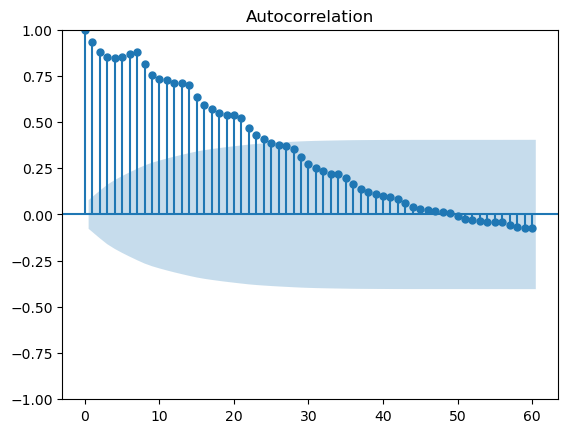

In [7]:
plot_acf(covid_cases.dropna(), lags=60)
plt.show()

La serie tiene **olas muy largas** (tendencia), así que la autocorrelación es alta en todos los lags y tapa el efecto semanal. Para verlo mejor se mira la ACF de la serie **diferenciada** (se quita la tendencia): si hay ciclo semanal aparecerán picos en los lags 7, 14, 21...

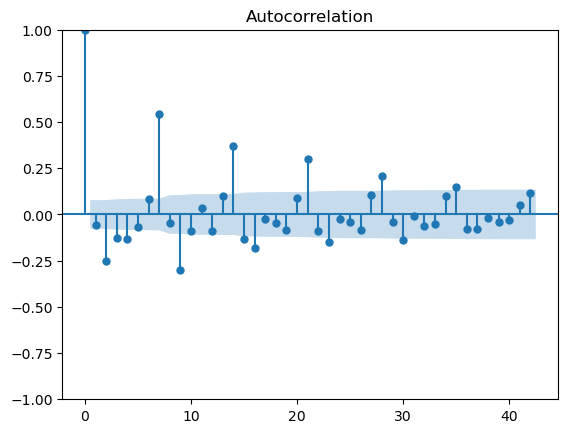

Umbral de significatividad (95%): ±0.078
ACF de la serie diferenciada, lag=3: -0.128
ACF de la serie diferenciada, lag=6: 0.086
ACF de la serie diferenciada, lag=7: 0.546
ACF de la serie diferenciada, lag=8: -0.046
ACF de la serie diferenciada, lag=14: 0.371
ACF de la serie diferenciada, lag=21: 0.302
ACF de la serie diferenciada, lag=28: 0.207

-> El lag 7 es significativo y es un máximo local: HAY componente estacional SEMANAL (period=7).


In [8]:
diff_cases = covid_cases.diff().dropna()

plot_acf(diff_cases, lags=42)
plt.show()

n = len(diff_cases)
acf_diff = acf(diff_cases, nlags=28)
umbral = 1.96 / np.sqrt(n)
print(f"Umbral de significatividad (95%): ±{umbral:.3f}")
for lag in [3, 6, 7, 8, 14, 21, 28]:
    print(f"ACF de la serie diferenciada, lag={lag}: {acf_diff[lag]:.3f}")

es_semanal = (acf_diff[7] > umbral) and (acf_diff[7] > acf_diff[6]) and (acf_diff[7] > acf_diff[8])
if es_semanal:
    print("\n-> El lag 7 es significativo y es un máximo local: HAY componente estacional SEMANAL (period=7).")
else:
    print("\n-> No se aprecia un pico claro en el lag 7: la estacionalidad semanal es débil.")

**Interpretación:** los casos diarios notificados suelen tener un patrón semanal (fines de semana con menos notificaciones y acumulación el lunes), por lo que el periodo natural es **`period=7`**.

El periodo anual (365) **no se puede estudiar** con estos datos: la serie cubre solo unos dos años y las variaciones grandes son *olas epidémicas* (no estaciones que se repitan), así que no hay forma de separar una estacionalidad anual de las propias olas.

### 0.2 Descomposición y residuo

`seasonal_decompose` con modelo multiplicativo exige valores estrictamente positivos. Si la serie tiene ceros (días sin casos nuevos), hay que usar el modelo **aditivo**.

Modelo de descomposición elegido: additive


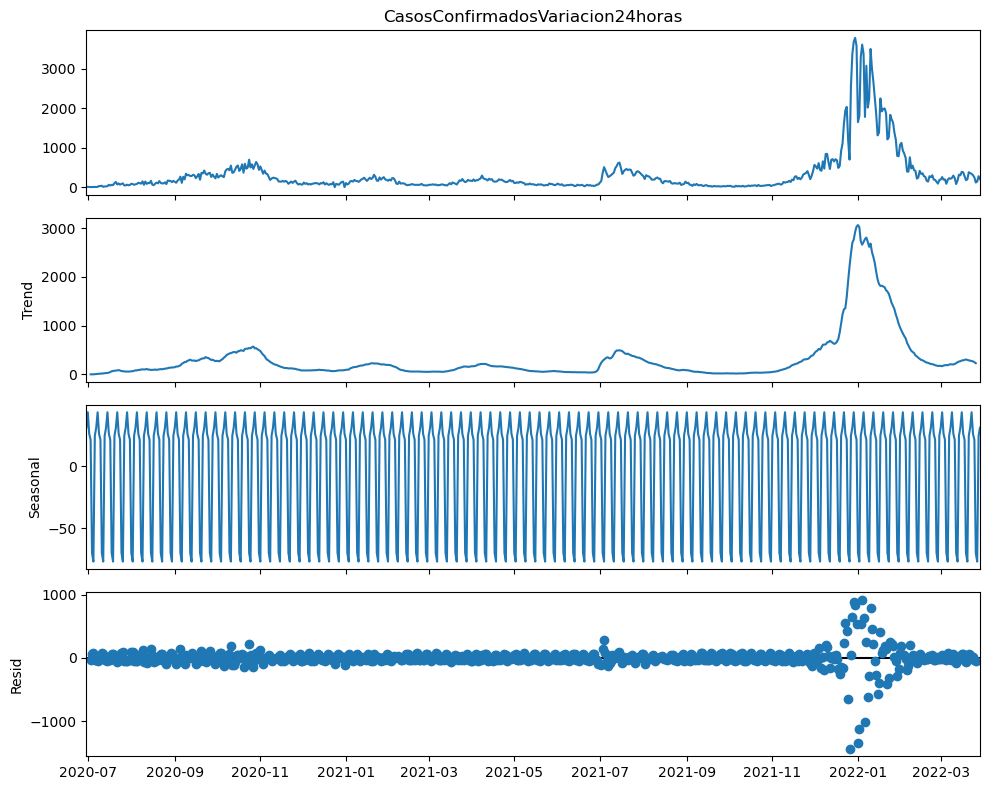

In [9]:
PERIODO = 7
modelo = 'additive' if (covid_cases <= 0).any() else 'multiplicative'
print("Modelo de descomposición elegido:", modelo)

decomposicion = seasonal_decompose(covid_cases, model=modelo, period=PERIODO)

fig = decomposicion.plot()
fig.set_size_inches(10, 8)
plt.tight_layout()
plt.show()

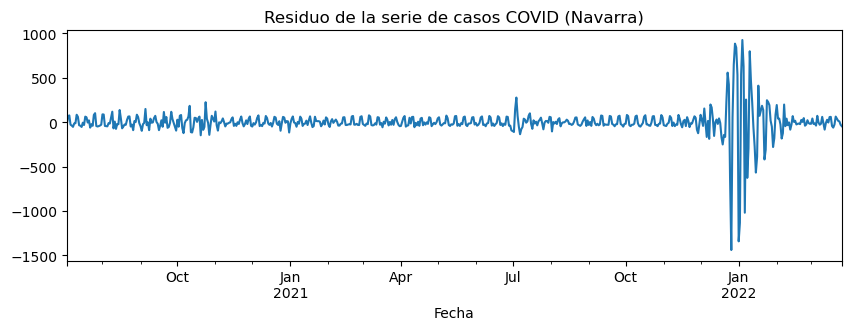

Fecha
2020-07-03   -24.876554
2020-07-04    69.192519
2020-07-05    76.439982
2020-07-06   -28.045733
2020-07-07   -37.401288
Name: resid, dtype: float64

In [10]:
residuo = decomposicion.resid.dropna()

residuo.plot(figsize=(10, 3), title='Residuo de la serie de casos COVID (Navarra)')
plt.show()

residuo.head()

### 0.3 Estacionariedad (tests de raíz unitaria)

- **ADF**: H0 = hay raíz unitaria (**no** estacionaria). p < 0.05 → se rechaza H0 → estacionaria.
- **KPSS**: H0 = la serie **es** estacionaria. p > 0.05 → no se rechaza H0 → estacionaria.

Se hacen sobre el **residuo** (como en el otro notebook) y, a modo de contraste, sobre la **serie original**.

In [11]:
def test_estacionariedad(serie, nombre):
    p_adf = adfuller(serie, autolag='AIC')[1]
    p_kpss = kpss(serie, regression='c', nlags='auto')[1]
    print(f"[{nombre}]")
    print(f"  adf  p-value: {p_adf:.6f}  -> {'estacionaria' if p_adf < 0.05 else 'NO estacionaria'}")
    print(f"  kpss p-value: {p_kpss:.6f}  -> {'estacionaria' if p_kpss > 0.05 else 'NO estacionaria'}")
    if p_adf < 0.05 and p_kpss > 0.05:
        veredicto = "ambos tests coinciden: ESTACIONARIA"
    elif p_adf >= 0.05 and p_kpss <= 0.05:
        veredicto = "ambos tests coinciden: NO estacionaria"
    else:
        veredicto = "los tests NO coinciden (conclusión ambigua; suele indicar tendencia/cambios de nivel)"
    print("  =>", veredicto, "\n")
    return p_adf, p_kpss

p_adf_orig, p_kpss_orig = test_estacionariedad(covid_cases.dropna(), "Serie original")
p_adf_res, p_kpss_res = test_estacionariedad(residuo, "Residuo de la descomposición")

[Serie original]
  adf  p-value: 0.047862  -> estacionaria
  kpss p-value: 0.014545  -> NO estacionaria
  => los tests NO coinciden (conclusión ambigua; suele indicar tendencia/cambios de nivel) 

[Residuo de la descomposición]
  adf  p-value: 0.000000  -> estacionaria
  kpss p-value: 0.100000  -> estacionaria
  => ambos tests coinciden: ESTACIONARIA 



### 0.4 Heterocedasticidad (test de Engle / ARCH)

H0 = la varianza del residuo es constante (homocedasticidad). p < 0.05 → se rechaza H0 → **hay heterocedasticidad**.

In [12]:
lm_test = het_arch(residuo)

print("Resultados del ARCH test:")
print(f"Estadístico LM: {lm_test[0]:.4f}")
print(f"P-valor LM: {lm_test[1]:.6f}")
print(f"Estadístico F: {lm_test[2]:.4f}")
print(f"P-valor F: {lm_test[3]:.6f}")

if lm_test[1] < 0.05:
    print("\n-> Se rechaza H0: el residuo presenta HETEROCEDASTICIDAD (la varianza no es constante).")
else:
    print("\n-> No se rechaza H0: no hay evidencia de heterocedasticidad.")

Resultados del ARCH test:
Estadístico LM: 335.5907
P-valor LM: 0.000000
Estadístico F: 71.5919
P-valor F: 0.000000

-> Se rechaza H0: el residuo presenta HETEROCEDASTICIDAD (la varianza no es constante).


In [13]:
# Resumen de lo que implica el análisis previo
print("RESUMEN DEL ANÁLISIS PREVIO")
print("-" * 60)
print(f"Estacionalidad semanal (period=7):  {'SÍ' if es_semanal else 'débil / no clara'}")
print(f"Modelo de descomposición:           {modelo}")
print(f"Serie original estacionaria:        {'SÍ' if (p_adf_orig < 0.05 and p_kpss_orig > 0.05) else 'NO / ambiguo'}")
print(f"Residuo estacionario:               {'SÍ' if (p_adf_res < 0.05 and p_kpss_res > 0.05) else 'NO / ambiguo'}")
print(f"Residuo heterocedástico (Engle):    {'SÍ' if lm_test[1] < 0.05 else 'NO'}")

RESUMEN DEL ANÁLISIS PREVIO
------------------------------------------------------------
Estacionalidad semanal (period=7):  SÍ
Modelo de descomposición:           additive
Serie original estacionaria:        NO / ambiguo
Residuo estacionario:               SÍ
Residuo heterocedástico (Engle):    SÍ


**Qué significa esto para el suavizado:**

- La serie tiene una **tendencia no constante** (olas) y un **ciclo semanal** que mete ruido regular. El objetivo del suavizado es quedarse con la tendencia/ola y eliminar ese ruido.
- Si hay estacionalidad semanal, la **media móvil de 7 días** es la elección natural: al promediar justo un ciclo completo, cada día de la semana pesa igual y el efecto semanal se cancela.
- Si el residuo es heterocedástico, la dispersión crece con el nivel de casos (más casos → más ruido). Un suavizador **robusto** como LOWESS (que reajusta pesos para reducir el efecto de atípicos) se comporta mejor en los picos que una media móvil simple.

Ahora se aplican los dos métodos.

### 1. Utilización de la media móvil

`rolling(window=k, center=True).mean()` promedia cada punto con los `k-1` vecinos que lo rodean. Con `center=True` la media queda alineada con el dato (sin retraso). Cuanto mayor es la ventana, más suave pero más se aplanan los picos.

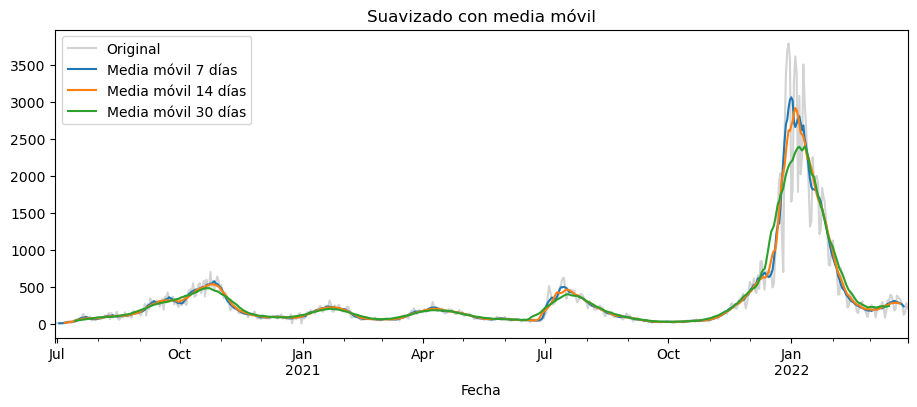

In [14]:
ventanas = [3, 7, 14, 30]
medias_moviles = {w: covid_cases.rolling(window=w, center=True).mean() for w in ventanas}

fig, ax = plt.subplots(figsize=(11, 4))
covid_cases.plot(ax=ax, color='lightgray', label='Original')
for w in [7, 14, 30]:
    medias_moviles[w].plot(ax=ax, label=f'Media móvil {w} días')
ax.set_title('Suavizado con media móvil')
ax.legend()
plt.show()

Zoom sobre la zona del pico máximo para ver el efecto de la ventana. Con `window=7` desaparecen las oscilaciones semanales; con `window=3` todavía quedan.

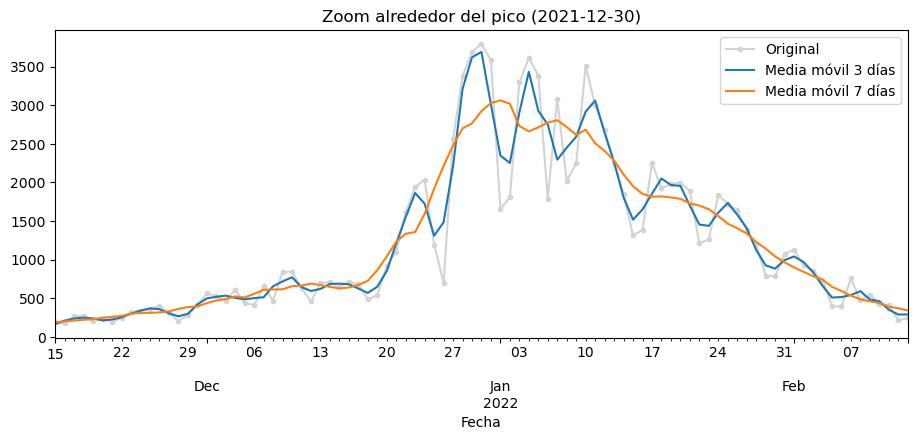

In [15]:
f_pico = covid_cases.idxmax()
zoom = slice(f_pico - pd.Timedelta(days=45), f_pico + pd.Timedelta(days=45))

fig, ax = plt.subplots(figsize=(11, 4))
covid_cases[zoom].plot(ax=ax, color='lightgray', marker='.', label='Original')
medias_moviles[3][zoom].plot(ax=ax, label='Media móvil 3 días')
medias_moviles[7][zoom].plot(ax=ax, label='Media móvil 7 días')
ax.set_title(f'Zoom alrededor del pico ({f_pico.date()})')
ax.legend()
plt.show()

**Conclusión (media móvil):** la ventana de **7 días** es la candidata natural: coincide con el periodo estacional, de modo que cada día de la semana pesa igual y el ciclo semanal se cancela sin aplanar demasiado las olas (se comprueba en el zoom y en la gráfica). Ventanas de 14 y 30 días suavizan más pero **recortan el pico** y ensanchan las olas; la de 3 días deja ruido semanal. Inconvenientes de la media móvil: pierde datos en los extremos (`NaN`) y todos los puntos de la ventana pesan igual, así que es sensible a atípicos.

### 2. Utilización de LOWESS

LOWESS (*locally weighted scatterplot smoothing*) ajusta una regresión lineal **local** ponderada alrededor de cada punto, usando una fracción `frac` de los datos. Un `frac` pequeño sigue más al dato (menos suave); uno grande suaviza más. Además, con `it=3` (por defecto) hace iteraciones robustas que rebajan el peso de los atípicos.

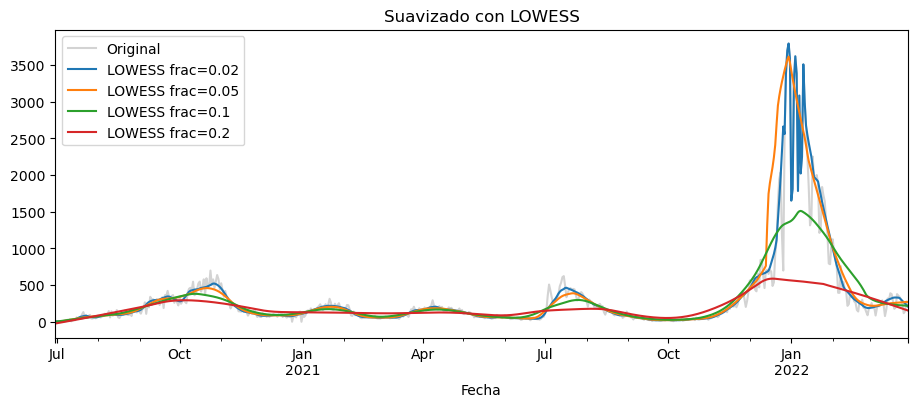

frac=0.02  -> cada ajuste local usa ~12 días
frac=0.05  -> cada ajuste local usa ~31 días
frac=0.1   -> cada ajuste local usa ~63 días
frac=0.2   -> cada ajuste local usa ~127 días


In [16]:
x = np.arange(len(covid_cases))
y = covid_cases.values

fracs = [0.02, 0.05, 0.10, 0.20]
lowess_res = {
    f: pd.Series(
        stm.nonparametric.lowess(y, x, frac=f, return_sorted=False),
        index=covid_cases.index
    )
    for f in fracs
}

fig, ax = plt.subplots(figsize=(11, 4))
covid_cases.plot(ax=ax, color='lightgray', label='Original')
for f in fracs:
    lowess_res[f].plot(ax=ax, label=f'LOWESS frac={f}')
ax.set_title('Suavizado con LOWESS')
ax.legend()
plt.show()

for f in fracs:
    print(f"frac={f:<5} -> cada ajuste local usa ~{int(f * len(y))} días")

**Conclusión (LOWESS):** con `frac=0.02` (~2 semanas) la curva sigue demasiado al dato y conserva parte del ruido semanal; con `frac=0.20` (~5 meses) se aplana y tiende a **perder las olas**. Un valor intermedio, **`frac≈0.05`** (~1 mes), es un buen compromiso: recoge la forma de cada ola eliminando el ruido de día a día (verificarlo en la gráfica). A diferencia de la media móvil, **no deja `NaN` en los extremos** y es más robusto a los valores atípicos.

### 3. Comparación de ambos métodos

Se comparan la **media móvil de 7 días** y **LOWESS (frac=0.05)** con dos medidas:

- **RMSE** frente a la serie original: cuánto se aleja el suavizado de los datos (menor = más fiel).
- **Rugosidad**: desviación típica de la primera diferencia de la serie suavizada (menor = más suave).

In [17]:
mm7 = medias_moviles[7]
lw05 = lowess_res[0.05]

comun = mm7.dropna().index          # mismo tramo para comparar de forma justa
metodos = {'Media móvil 7': mm7, 'LOWESS 0.05': lw05}

filas = []
for nombre, s in metodos.items():
    rmse = np.sqrt(((covid_cases[comun] - s[comun]) ** 2).mean())
    rugosidad = s[comun].diff().std()
    filas.append({'Método': nombre, 'RMSE vs original': rmse, 'Rugosidad': rugosidad})

tabla = pd.DataFrame(filas).set_index('Método').round(2)
tabla

,RMSE vs original,Rugosidad
Método,,
Media móvil 7,163.74,38.73
LOWESS 0.05,266.76,41.01


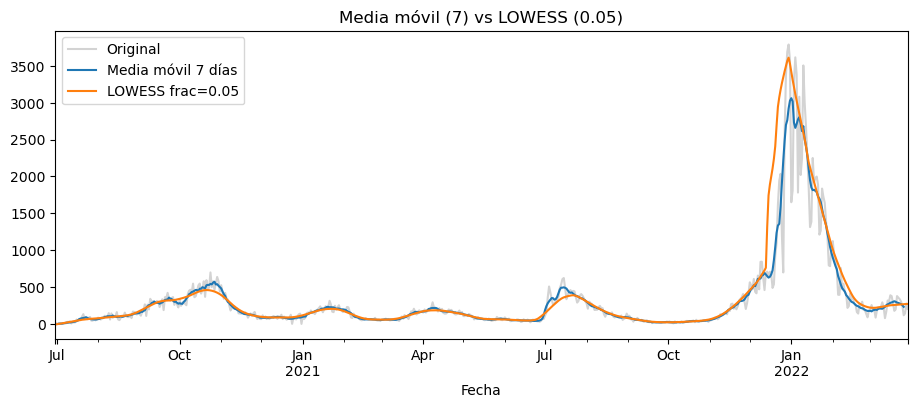

In [18]:
fig, ax = plt.subplots(figsize=(11, 4))
covid_cases.plot(ax=ax, color='lightgray', label='Original')
mm7.plot(ax=ax, label='Media móvil 7 días')
lw05.plot(ax=ax, label='LOWESS frac=0.05')
ax.set_title('Media móvil (7) vs LOWESS (0.05)')
ax.legend()
plt.show()

In [19]:
mas_suave = tabla['Rugosidad'].idxmin()
mas_fiel = tabla['RMSE vs original'].idxmin()
print(f"Más suave (menor rugosidad):      {mas_suave}")
print(f"Más fiel a los datos (menor RMSE): {mas_fiel}")

Más suave (menor rugosidad):      Media móvil 7
Más fiel a los datos (menor RMSE): Media móvil 7


### Conclusión final

- La serie de casos diarios de COVID en Navarra tiene olas con tendencia no constante (la serie original no es estacionaria) y, como se espera en datos de notificación diaria, un **ciclo semanal** (`period=7`) y una varianza que crece con el nivel de casos (heterocedasticidad). Los valores concretos de ADF, KPSS y Engle se imprimen en la celda resumen de la sección 0.
- **Media móvil de 7 días**: simple, interpretable y elimina exactamente el ciclo semanal; pero pierde datos en los extremos y es sensible a atípicos.
- **LOWESS**: suavizado más flexible y robusto, sin pérdida de datos en los extremos; requiere elegir bien `frac` (compromiso entre ruido y pérdida de forma).
- Para esta serie, ambos con parámetros adecuados (ventana 7 / `frac≈0.05`) dan resultados muy parecidos; la media móvil es preferible si se quiere explicar fácilmente la limpieza del efecto semanal, y LOWESS si se quiere una curva continua y más robusta en los picos.